# ViT XAI

## Imports

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
import timm

from monai.transforms import (
    Compose,
    LoadImage,
    EnsureChannelFirst,
    Resize,
    ScaleIntensity,
    EnsureType,
)

C:\Users\user\anaconda3\envs\monai\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Config + Check GPU

In [2]:
PROJECT_DIR = r"C:\Users\user\Desktop\MONAI"

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "models",
    "vit_base_patch16_224.pt"
)

DATA_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "brain-tumor-mri-classification",
    "merged_dataset_v3",
    "images"
)

TEST_DIR = os.path.join(DATA_DIR, "test")

class_names = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 5070


## Load Model

In [3]:
model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=False,
    num_classes=4
)

model = model.to(device)

In [4]:
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device
)

print(type(checkpoint))

if isinstance(checkpoint, dict):
    print(checkpoint.keys())

<class 'collections.OrderedDict'>
odict_keys(['cls_token', 'pos_embed', 'patch_embed.proj.weight', 'patch_embed.proj.bias', 'blocks.0.norm1.weight', 'blocks.0.norm1.bias', 'blocks.0.attn.qkv.weight', 'blocks.0.attn.qkv.bias', 'blocks.0.attn.proj.weight', 'blocks.0.attn.proj.bias', 'blocks.0.norm2.weight', 'blocks.0.norm2.bias', 'blocks.0.mlp.fc1.weight', 'blocks.0.mlp.fc1.bias', 'blocks.0.mlp.fc2.weight', 'blocks.0.mlp.fc2.bias', 'blocks.1.norm1.weight', 'blocks.1.norm1.bias', 'blocks.1.attn.qkv.weight', 'blocks.1.attn.qkv.bias', 'blocks.1.attn.proj.weight', 'blocks.1.attn.proj.bias', 'blocks.1.norm2.weight', 'blocks.1.norm2.bias', 'blocks.1.mlp.fc1.weight', 'blocks.1.mlp.fc1.bias', 'blocks.1.mlp.fc2.weight', 'blocks.1.mlp.fc2.bias', 'blocks.2.norm1.weight', 'blocks.2.norm1.bias', 'blocks.2.attn.qkv.weight', 'blocks.2.attn.qkv.bias', 'blocks.2.attn.proj.weight', 'blocks.2.attn.proj.bias', 'blocks.2.norm2.weight', 'blocks.2.norm2.bias', 'blocks.2.mlp.fc1.weight', 'blocks.2.mlp.fc1.bias'

In [5]:
model.load_state_dict(checkpoint)

model.eval()

print("ViT loaded successfully!")

ViT loaded successfully!


In [6]:
transform = Compose([
    LoadImage(image_only=True),
    EnsureChannelFirst(),
    Resize((224, 224)),
    ScaleIntensity(),
    EnsureType(),
])

## Select 8 random images

In [7]:
random.seed(42)

selected_images = []

for class_name in class_names:

    class_dir = os.path.join(
        TEST_DIR,
        class_name
    )

    images = [
        os.path.join(class_dir, f)
        for f in os.listdir(class_dir)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp")
        )
    ]

    selected = random.sample(
        images,
        min(2, len(images))
    )

    for image_path in selected:
        selected_images.append({
            "path": image_path,
            "true_class": class_name
        })

print("Selected:", len(selected_images))

for item in selected_images:
    print(
        item["true_class"],
        "->",
        os.path.basename(item["path"])
    )

Selected: 8
glioma -> rf_test_glioma_739.jpg
glioma -> rf_test_glioma_728.jpg
meningioma -> rf_test_meningioma_538.jpg
meningioma -> rf_test_meningioma_508.jpg
no_tumor -> rf_test_no_tumor_450.jpg
no_tumor -> rf_test_no_tumor_449.jpg
pituitary -> rf_test_pituitary_558.jpg
pituitary -> rf_test_pituitary_597.jpg


In [8]:
for name, module in model.named_modules():
    print(name, "->", type(module).__name__)

 -> VisionTransformer
patch_embed -> PatchEmbed
patch_embed.proj -> Conv2d
patch_embed.norm -> Identity
pos_drop -> Dropout
patch_drop -> Identity
norm_pre -> Identity
blocks -> Sequential
blocks.0 -> Block
blocks.0.norm1 -> LayerNorm
blocks.0.attn -> Attention
blocks.0.attn.qkv -> Linear
blocks.0.attn.q_norm -> Identity
blocks.0.attn.k_norm -> Identity
blocks.0.attn.attn_drop -> Dropout
blocks.0.attn.norm -> Identity
blocks.0.attn.proj -> Linear
blocks.0.attn.proj_drop -> Dropout
blocks.0.ls1 -> Identity
blocks.0.drop_path1 -> Identity
blocks.0.norm2 -> LayerNorm
blocks.0.mlp -> Mlp
blocks.0.mlp.fc1 -> Linear
blocks.0.mlp.act -> GELU
blocks.0.mlp.drop1 -> Dropout
blocks.0.mlp.norm -> Identity
blocks.0.mlp.fc2 -> Linear
blocks.0.mlp.drop2 -> Dropout
blocks.0.ls2 -> Identity
blocks.0.drop_path2 -> Identity
blocks.1 -> Block
blocks.1.norm1 -> LayerNorm
blocks.1.attn -> Attention
blocks.1.attn.qkv -> Linear
blocks.1.attn.q_norm -> Identity
blocks.1.attn.k_norm -> Identity
blocks.1.attn.at

In [9]:
target_layer = model.blocks[-1].norm1

print(target_layer)

LayerNorm((768,), eps=1e-06, elementwise_affine=True)


## Apply GRAD CAM

In [18]:
def generate_vit_xai(model, image_path, target_layer):

    activations = None
    gradients = None

    def forward_hook(module, inputs, output):
        nonlocal activations
        activations = output

    def backward_hook(module, grad_input, grad_output):
        nonlocal gradients
        gradients = grad_output[0]

    forward_handle = target_layer.register_forward_hook(
        forward_hook
    )

    backward_handle = target_layer.register_full_backward_hook(
        backward_hook
    )

    # -----------------------------------------
    # Load image
    # -----------------------------------------

    image = transform(image_path)

    input_tensor = image.unsqueeze(0).to(device)

    # -----------------------------------------
    # Forward
    # -----------------------------------------

    model.zero_grad()

    output = model(input_tensor)

    probabilities = F.softmax(output, dim=1)

    predicted_class = output.argmax(dim=1).item()

    confidence = probabilities[
        0, predicted_class
    ].item()

    # -----------------------------------------
    # Backward
    # -----------------------------------------

    score = output[
        0, predicted_class
    ]

    score.backward()

    # -----------------------------------------
    # Get activations + gradients
    # -----------------------------------------

    activations = activations.detach()
    gradients = gradients.detach()

    print("Activations:", activations.shape)
    print("Gradients:", gradients.shape)

    # -----------------------------------------
    # Remove CLS token
    # -----------------------------------------

    activations = activations[:, 1:, :]
    gradients = gradients[:, 1:, :]

    # Shape:
    # [1, 196, 768]

    # -----------------------------------------
    # Patch importance
    #
    # Each patch gets one importance value.
    # -----------------------------------------

    cam = (
        gradients * activations
    ).sum(dim=-1)

    # Shape:
    # [1, 196]

    cam = cam.squeeze(0)

    # -----------------------------------------
    # Keep positive contributions
    # -----------------------------------------

    cam = F.relu(cam)

    # -----------------------------------------
    # 196 patches -> 14 x 14
    # -----------------------------------------

    cam = cam.reshape(14, 14)

    # -----------------------------------------
    # Normalize
    # -----------------------------------------

    cam_min = cam.min()
    cam_max = cam.max()

    if cam_max > cam_min:
        cam = (
            cam - cam_min
        ) / (
            cam_max - cam_min
        )
    else:
        cam = torch.zeros_like(cam)

    # -----------------------------------------
    # Resize patch map -> 224 x 224
    # -----------------------------------------

    cam = F.interpolate(
        cam.unsqueeze(0).unsqueeze(0),
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = cam.squeeze().cpu().numpy()

    # -----------------------------------------
    # Prepare image
    # -----------------------------------------

    display_image = (
        image
        .detach()
        .cpu()
        .numpy()
        .transpose(1, 2, 0)
    )

    display_image = (
        display_image - display_image.min()
    )

    if display_image.max() > 0:
        display_image = (
            display_image /
            display_image.max()
        )

    # -----------------------------------------
    # Remove hooks
    # -----------------------------------------

    forward_handle.remove()
    backward_handle.remove()

    return (
        display_image,
        cam,
        predicted_class,
        confidence
    )

In [21]:
results = []

for item in selected_images:

    print(
        f"Processing: {item['true_class']} -> "
        f"{os.path.basename(item['path'])}"
    )

    (
        image,
        cam,
        predicted_class,
        confidence
    ) = generate_vit_xai(
        model,
        item["path"],
        target_layer
    )

    results.append({
        "path": item["path"],
        "true_class": item["true_class"],
        "predicted_class": class_names[predicted_class],
        "confidence": confidence,
        "image": image,
        "cam": cam
    })

print("\nCompleted:", len(results), "images")

Processing: glioma -> rf_test_glioma_739.jpg
Activations: torch.Size([1, 197, 768])
Gradients: torch.Size([1, 197, 768])
Processing: glioma -> rf_test_glioma_728.jpg
Activations: torch.Size([1, 197, 768])
Gradients: torch.Size([1, 197, 768])
Processing: meningioma -> rf_test_meningioma_538.jpg
Activations: torch.Size([1, 197, 768])
Gradients: torch.Size([1, 197, 768])
Processing: meningioma -> rf_test_meningioma_508.jpg
Activations: torch.Size([1, 197, 768])
Gradients: torch.Size([1, 197, 768])
Processing: no_tumor -> rf_test_no_tumor_450.jpg
Activations: torch.Size([1, 197, 768])
Gradients: torch.Size([1, 197, 768])
Processing: no_tumor -> rf_test_no_tumor_449.jpg
Activations: torch.Size([1, 197, 768])
Gradients: torch.Size([1, 197, 768])
Processing: pituitary -> rf_test_pituitary_558.jpg
Activations: torch.Size([1, 197, 768])
Gradients: torch.Size([1, 197, 768])
Processing: pituitary -> rf_test_pituitary_597.jpg
Activations: torch.Size([1, 197, 768])
Gradients: torch.Size([1, 197, 76

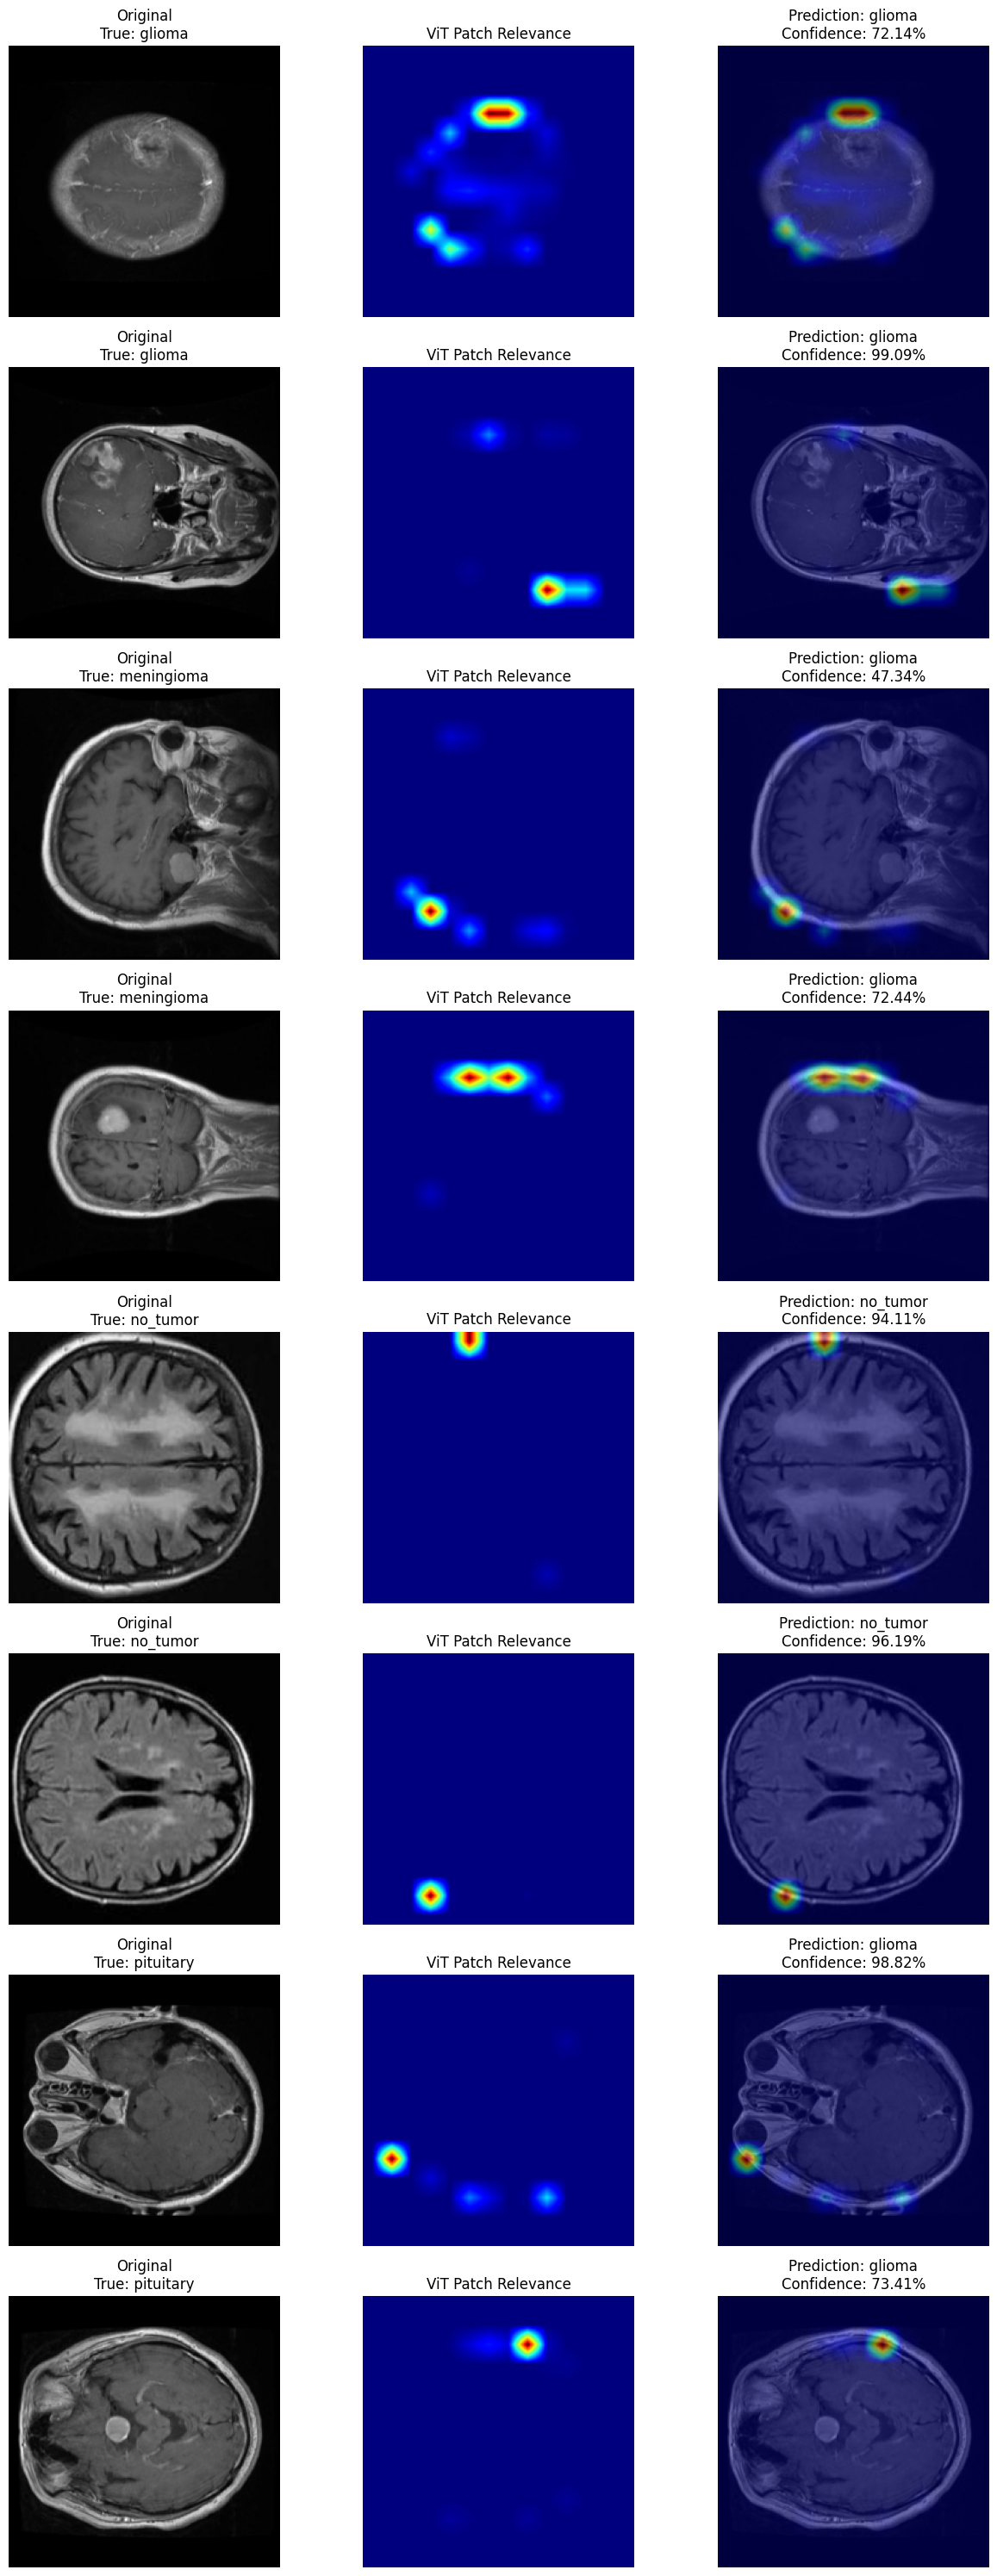

In [22]:
fig, axes = plt.subplots(
    8,
    3,
    figsize=(13, 30)
)

for i, result in enumerate(results):

    image = result["image"]
    cam = result["cam"]

    true_class = result["true_class"]
    predicted_class = result["predicted_class"]
    confidence = result["confidence"]

    # --------------------------------
    # Original
    # --------------------------------

    axes[i, 0].imshow(image)

    axes[i, 0].set_title(
        f"Original\n"
        f"True: {true_class}"
    )

    axes[i, 0].axis("off")

    # --------------------------------
    # XAI heatmap
    # --------------------------------

    axes[i, 1].imshow(
        cam,
        cmap="jet"
    )

    axes[i, 1].set_title(
        "ViT Patch Relevance"
    )

    axes[i, 1].axis("off")

    # --------------------------------
    # Overlay
    # --------------------------------

    axes[i, 2].imshow(image)

    axes[i, 2].imshow(
        cam,
        cmap="jet",
        alpha=0.5
    )

    axes[i, 2].set_title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2%}"
    )

    axes[i, 2].axis("off")


plt.tight_layout()
plt.show()